# The code draws validation plots of protein models against specified metrics. Quality zones can be adjusted. Metrics are obtained from Molprobity.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rc('font', family='Noto Sans')

In [3]:
# data (mock data)

labels = ["prot1", "prot2"]
mock_data = {
    "Length": [0.014, 0.008],
    "Angle": [2.1, 1.3],
    "RamaZ": [3.2, 1.8],
    "CaBLAM": [5.2, 0.8],
    "Clash": [22.0, 8.5],
    "MolProbity": [2.8, 1.4]
}
data = pd.DataFrame(mock_data, index=labels)

In [4]:
# metric limits

metric_limit = {
    "Length": (0.010, 0.015, 0.020), 
    "Angle": (1.5, 2.0, 2.5), 
    "RamaZ": (2.0, 3.0, 4.0), 
    "CaBLAM": (1.0, 5.0, 6.0), 
    "Clash": (10.0, 20.0, 25.0), 
    "MolProbity": (1.5, 2.5, 3.5),
    "Rotamer": (0.3, 1.0, 2.5)
}

In [5]:
def apply_validation_zones (ax, thresholds):
    """
    Apply validation zones to the specified plot with labels
    """

    great_lim, avg_lim, poor_lim = thresholds
    ax.set_ylim(ymax=max(thresholds))

    # Great zone (green)
    ax.axhspan(0, great_lim, facecolor='green', alpha=0.5)
    ax.text(0.5, great_lim/2, 'Great', color="#4B714E", horizontalalignment='center', fontweight="bold", verticalalignment='center', fontsize=17)

    # Average zone (yellow)
    ax.axhspan(great_lim, avg_lim, facecolor='yellow', alpha=0.5)
    ax.text(0.5, (great_lim+avg_lim)/2, 'Average', color="#939351", horizontalalignment='center', fontweight="bold", verticalalignment='center', fontsize=17)

    # Poor zone (red)
    ax.axhspan(avg_lim, poor_lim, facecolor='red', alpha=0.5)
    ax.text(0.5, (avg_lim + poor_lim)/2, 'Poor', color="#943A3D", horizontalalignment='center', fontweight="bold", verticalalignment='center', fontsize=17)

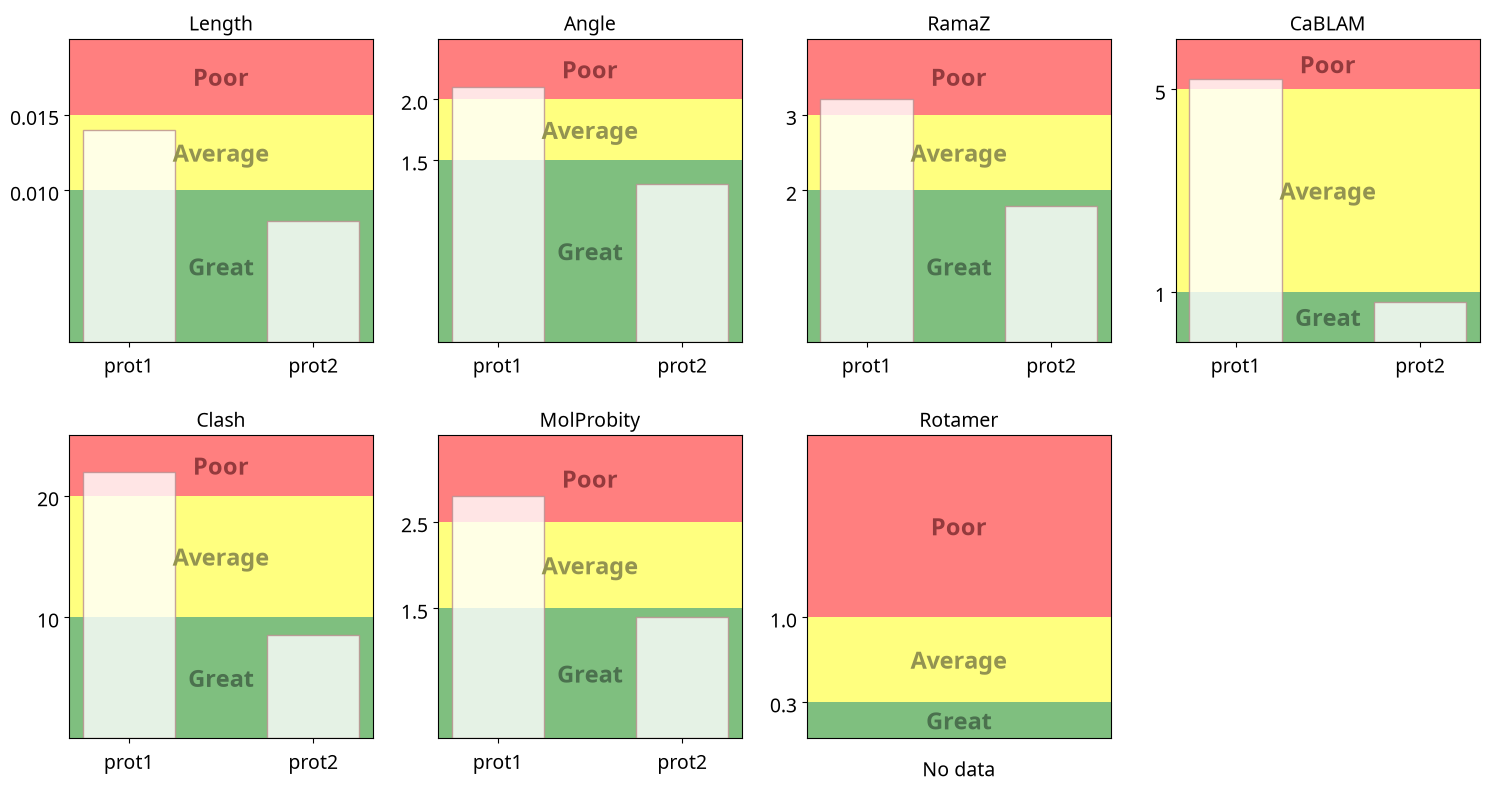

In [6]:
# Plotting and saving the figure

# calculate the net depending on the number of metrics
n_metrics = len(metric_limit)
n_cols = 4
n_rows = (n_metrics + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes_flat = axes.flatten() if n_metrics > 1 else [axes]

for i, (metric_name, thresholds) in enumerate(metric_limit.items()):

    ax = axes_flat[i]
    apply_validation_zones(ax, thresholds)
    if metric_name in data.columns:
        ax.bar(labels, data[metric_name], width=0.5, alpha=0.8, color="white", edgecolor="#BA8E90")
    else:
        ax.text(0.5, -0.1, "No data", transform=ax.transAxes, horizontalalignment='center', verticalalignment='center', fontsize=14)
        ax.set_xticks([])
    ax.set_title(metric_name, fontsize=14)
    ax.set_yticks(thresholds[:2])
    ax.tick_params(labelsize=14)

for j in range(i + 1, len(axes_flat)): # remove unused axes
    fig.delaxes(axes_flat[j])

fig.tight_layout(h_pad=2.0, w_pad=2.0)
plt.savefig("table_1_graph.svg", dpi=300)